# **Prediksi Kelangsungan Hidup Karakter Game of Thrones Denga Random Forest**

Sebuah platform analisis media dan penerbitan buku novel ingin membangun sistem
kecerdasan buatan berbasis Machine Learning untuk memprediksi tingkat kelangsungan
hidup (survival rate) atau potensi kematian karakter dalam serial novel populer Game of
Thrones / A Song of Ice and Fire secara otomatis berdasarkan atribut demografis, latar
belakang klan/house, serta keterlibatan dalam setiap buku tanpa perlu dianalisis secara
manual.
Dataset ini telah merekam berbagai karakteristik karakter novel, di mana setiap sampel
direpresentasikan oleh 29 fitur atribut. Tim analis bertugas membangun model machine
learning berbasis Random Forest Classifier untuk memprediksi variabel target biner status
kelangsungan hidup karakter (isAlive: 0 = Meninggal, 1 = Masih Hidup) berdasarkan pola
fitur yang terkandung di dalam tiap baris data.

# **1. Business Understanding**


## **1.1 Latar Belakang**

Sebuah tim analis media dan penerbitan buku novel inign membangun machine learning untuk meprediksi tingkat kelangs hidup dari novel Game of Thrones.

## **1.2 Tujuan**

Membangun machine learning menggunakan Random Forest untuk memprediksi tingkat kelangsungan hidup karakter.

## **1.3 Masalah**

Dalam menganalisis data, tim analis masih menggunakan cara manual sehingga memperlukan waktu yang lama dan tidak efesien.

## **1.4 Solusi**

Membangun machine learning dengan menggunakan Random Forest untuk memprediksi tingkat kelangsungan hidup karakter.

## **1.5 Deskripsi Tabbel**

`Fitur Input (X): 29 kolom atribut latar belakang karakter dan keterlibatan cerita, yang meliputi : `
- S.No: Nomor urut identifikasi data (fitur indeks/ID).
- plod: Nilai estimasi probabilitas kematian berdasarkan analisis statistik (Probability of Life or Death).
- name: Nama lengkap karakter.
- title: Gelar/jabatan karakter (misal: Lord, Ser, Queen).
- gender: Jenis kelamin karakter (Kategori biner: 1 untuk Pria, 0 untuk Wanita).
- culture: Latar belakang kebudayaan/suku asal karakter (misal: Rivermen,
Dornish, Northmen).
- dateOfBirth: Tahun kelahiran karakter (satuan: Tahun/Era Westeros).
- DateoFdeath: Tahun kematian karakter (jika sudah meninggal).
- mother: Nama ibu dari karakter.
- father: Nama ayah dari karakter.
- heir: Nama ahli waris dari karakter.
- house: Nama klan/keluarga (House) utama (misal: House Stark, House
Lannister, House Targaryen).
- spouse: Nama pasangan/suami/istri dari karakter.
-  book1: Indikator kemunculan karakter pada Buku 1 (A Game of Thrones)
(Kategori biner: 1 muncul, 0 tidak).
- book2: Indikator kemunculan karakter pada Buku 2 (A Clash of Kings)
(Kategori biner: 1 muncul, 0 tidak).
- book3: Indikator kemunculan karakter pada Buku 3 (A Storm of Swords)
(Kategori biner: 1 muncul, 0 tidak).
- book4: Indikat    or kemunculan karakter pada Buku 4 (A Feast for Crows)
(Kategori biner: 1 muncul, 0 tidak).
-  book5: Indikator kemunculan karakter pada Buku 5 (A Dance with Dragons)
(Kategori biner: 1 muncul, 0 tidak).
-  isAliveMother: Status kelangsungan hidup ibu karakter (Kategori biner: 1
hidup, 0 meninggal).
-  isAliveFather: Status kelangsungan hidup ayah karakter (Kategori biner: 1
hidup, 0 meninggal).
-  isAliveHeir: Status kelangsungan hidup ahli waris (Kategori biner: 1 hidup, 0
meninggal).
-  isAliveSpouse: Status kelangsungan hidup pasangan (Kategori biner: 1
hidup, 0 meninggal).
-  isMarried: Status pernikahan karakter (Kategori biner: 1 menikah, 0 tidak).
-  isNoble: Status kebangsawaan karakter (Kategori biner: 1 bangsawan, 0
rakyat biasa).
-  age: Usia karakter (satuan: Tahun)
-  numDeadRelations: Jumlah kerabat/keluarga dekat karakter yang telah
meninggal (satuan: Orang).
-  boolDeadRelations: Indikator apakah karakter memiliki kerabat yang
meninggal (Kategori biner: 1 ya, 0 tidak).
-  isPopular: Indikator apakah karakter merupakan tokoh populer (Kategori
biner: 1 ya, 0 tidak).
-  popularity: Skor tingkat popularitas karakter dalam cerita (satuan: Skala rasio
0.0 sampai 1.0).

` Target Label (Y): ` 
Kolom isAlive di bagian akhir yang berisi angka biner (0 = Karakter Meninggal, 1 = Karakter Masih Hidup).

Daftar Isi

1. <a href="#Data_Preparation">Data Preparation</a>
2. <a href="#Exploratory_Data_Analysis">Exploratory Data Analysis</a>
3. <a href="#Data_Pre_Processing">Data Pre Processing</a>


# **<span id="2. Data Preparation" style="color: #2563EB;">2. Data Preparation</span>**

In [386]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tkinter as tk
import random

In [387]:
df = pd.read_csv('../dataset/HW2.csv')
df.head(10)

,S.No,plod,name,title,gender,culture,dateOfBirth,DateoFdeath,mother,father,...,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,boolDeadRelations,isPopular,popularity,isAlive
0,1,0.946,Viserys II Targaryen,NaN,1,NaN,NaN,NaN,Rhaenyra Targaryen,Daemon Targaryen,...,0.0,NaN,0,0,NaN,11,1,1,0.605351,0
1,2,0.613,Walder Frey,Lord of the Crossing,1,Rivermen,208.0,NaN,NaN,NaN,...,NaN,1.0,1,1,97.0,1,1,1,0.896321,1
2,3,0.507,Addison Hill,Ser,1,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0,1,NaN,0,0,0,0.267559,1
3,4,0.924,Aemma Arryn,Queen,0,NaN,82.0,105.0,NaN,NaN,...,NaN,0.0,1,1,23.0,0,0,0,0.183946,0
4,5,0.383,Sylva Santagar,Greenstone,0,Dornish,276.0,NaN,NaN,NaN,...,NaN,1.0,1,1,29.0,0,0,0,0.043478,1
5,6,0.979,Tommen Baratheon,NaN,1,NaN,NaN,NaN,Cersei Lannister,Robert Baratheon,...,1.0,NaN,0,0,NaN,5,1,1,1.000000,1
6,7,0.986,Valarr Targaryen,Hand of the King,1,Valyrian,183.0,209.0,NaN,NaN,...,NaN,1.0,1,1,26.0,0,0,1,0.431438,0
7,8,0.964,Viserys I Targaryen,NaN,1,NaN,NaN,NaN,Alyssa Targaryen,Baelon Targaryen,...,1.0,NaN,0,0,NaN,5,1,1,0.678930,0
8,9,0.276,Wilbert,Ser,1,NaN,NaN,298.0,NaN,NaN,...,NaN,NaN,0,1,NaN,0,0,0,0.006689,0
9,10,0.609,Wilbert Osgrey,Ser,1,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0,1,NaN,0,0,0,0.020067,1


In [388]:
df.info()
df.describe()
print('========================================================')
df.size


<class 'pandas.DataFrame'>
RangeIndex: 1946 entries, 0 to 1945
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No               1946 non-null   int64  
 1   plod               1946 non-null   float64
 2   name               1946 non-null   str    
 3   title              938 non-null    str    
 4   gender             1946 non-null   int64  
 5   culture            677 non-null    str    
 6   dateOfBirth        433 non-null    float64
 7   DateoFdeath        444 non-null    float64
 8   mother             21 non-null     str    
 9   father             26 non-null     str    
 10  heir               23 non-null     str    
 11  house              1519 non-null   str    
 12  spouse             276 non-null    str    
 13  book1              1946 non-null   int64  
 14  book2              1946 non-null   int64  
 15  book3              1946 non-null   int64  
 16  book4              1946 non-null   

58380

In [389]:
null = pd.DataFrame({'Missing Value': df.isnull().sum(), 'Persentase': df.isnull().sum() / len(df) * 100})
null.sort_values(by='Missing Value', ascending=False)


,Missing Value,Persentase
mother,1925,98.920863
isAliveMother,1925,98.920863
isAliveHeir,1923,98.818088
heir,1923,98.818088
father,1920,98.663926
isAliveFather,1920,98.663926
isAliveSpouse,1670,85.817061
spouse,1670,85.817061
dateOfBirth,1513,77.749229
age,1513,77.749229


In [390]:
df.duplicated().sum()

np.int64(0)

<h1 id="Exploratory_Data_Analysis" style="color: #C83232; font-weight: bold; font-size: 70px;">3. EDA</h1>


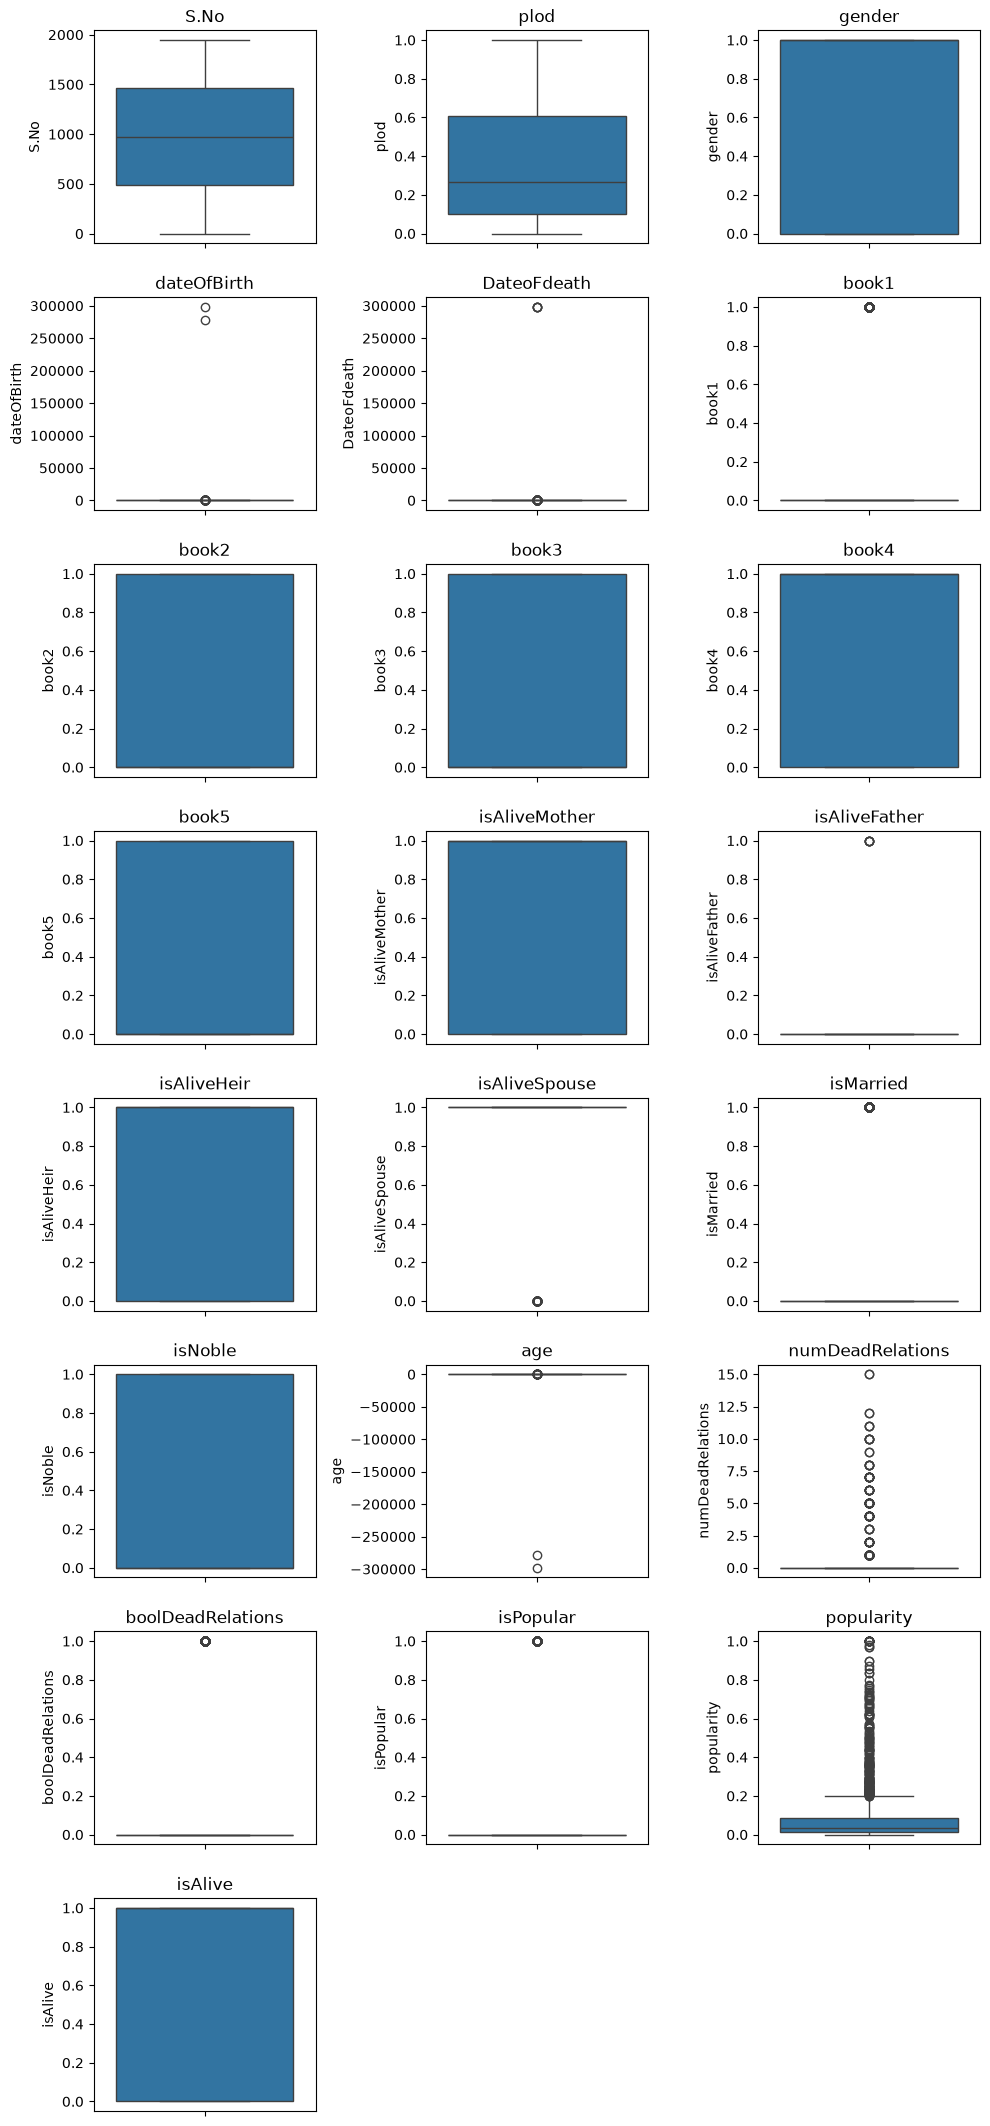

In [391]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(10, 40))

for i, column in enumerate(cols, start=1):
    plt.subplot(15, 3, i)
    sns.boxplot(df[column])
    plt.title(column)

plt.tight_layout(h_pad=2)
plt.show()

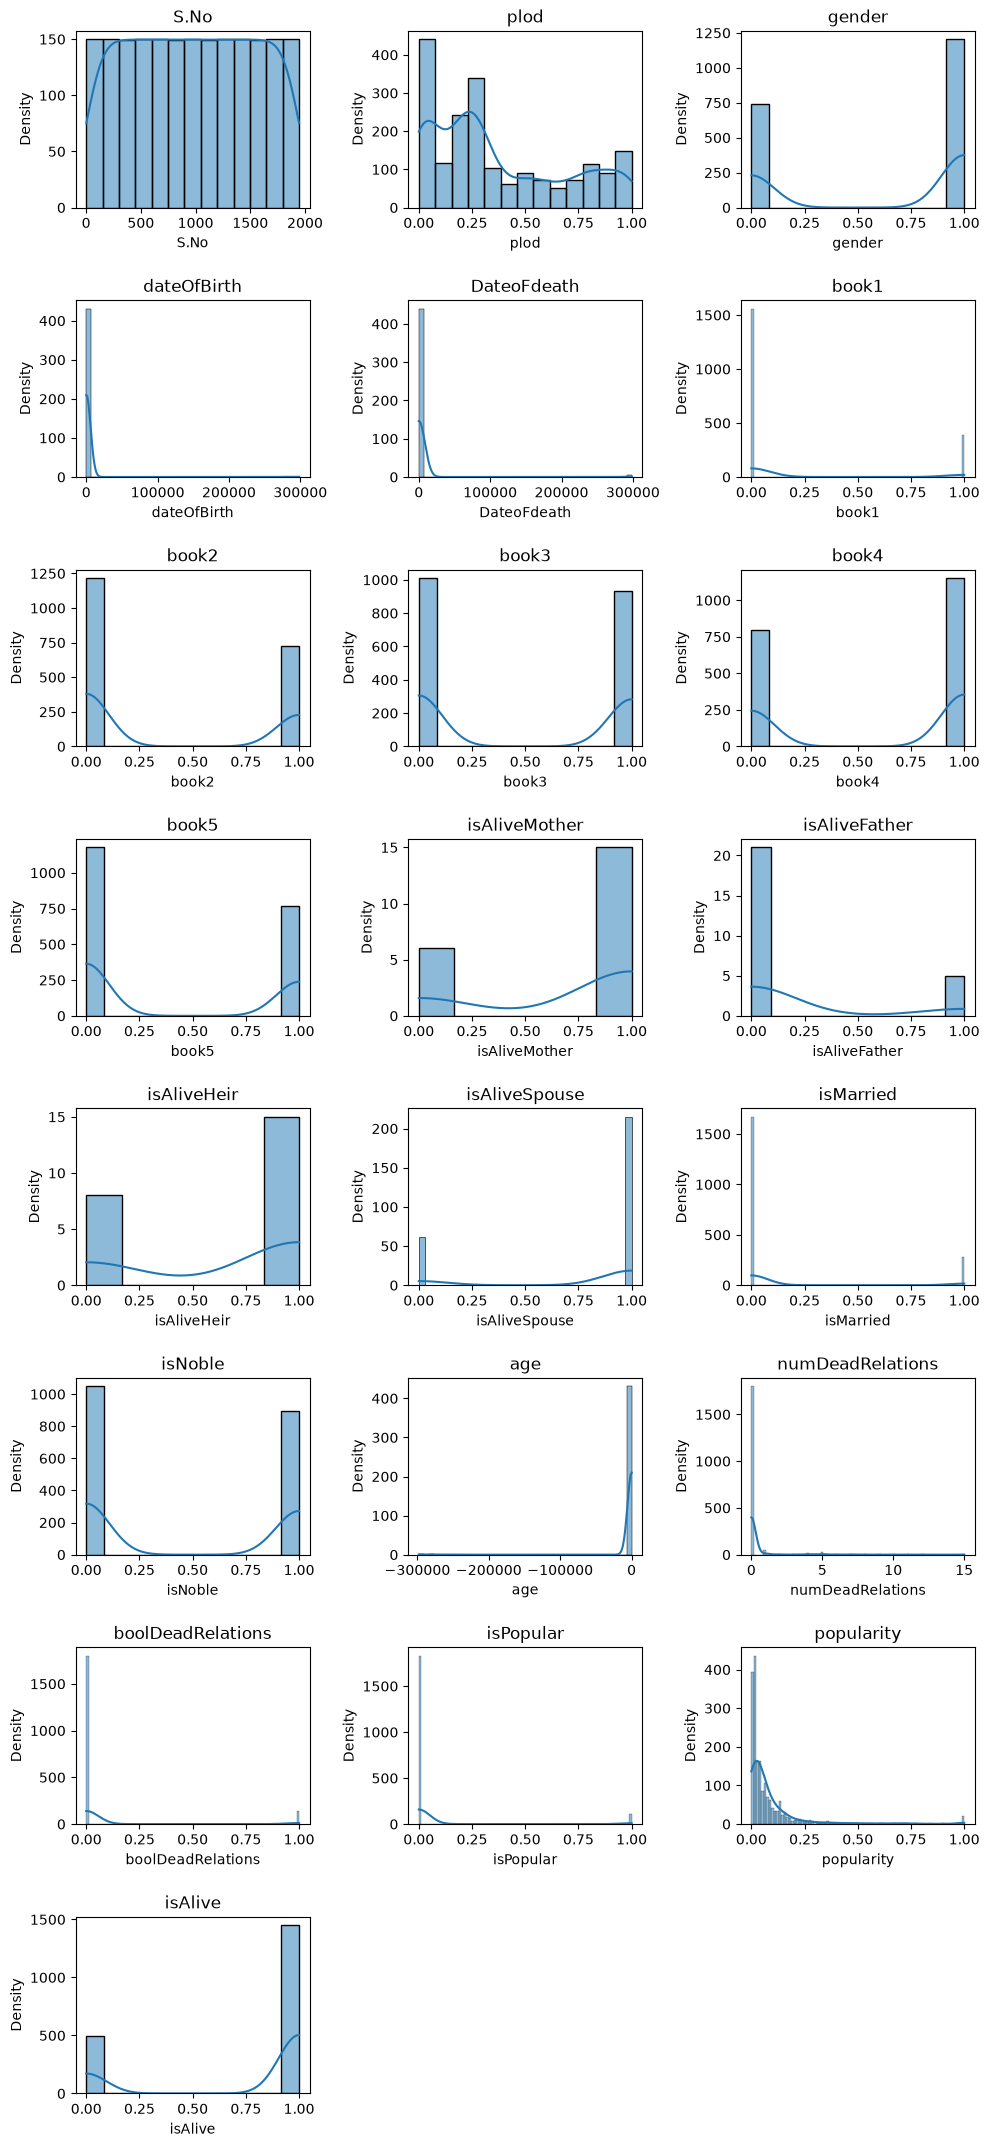

In [392]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(10, 40))

for i, column in enumerate(cols, start=1):
    plt.subplot(15, 3, i)
    sns.histplot(df[column], kde=True)
    plt.xlabel(column)
    plt.ylabel('Density')
    plt.title(column)

plt.tight_layout(h_pad=2)
plt.show()

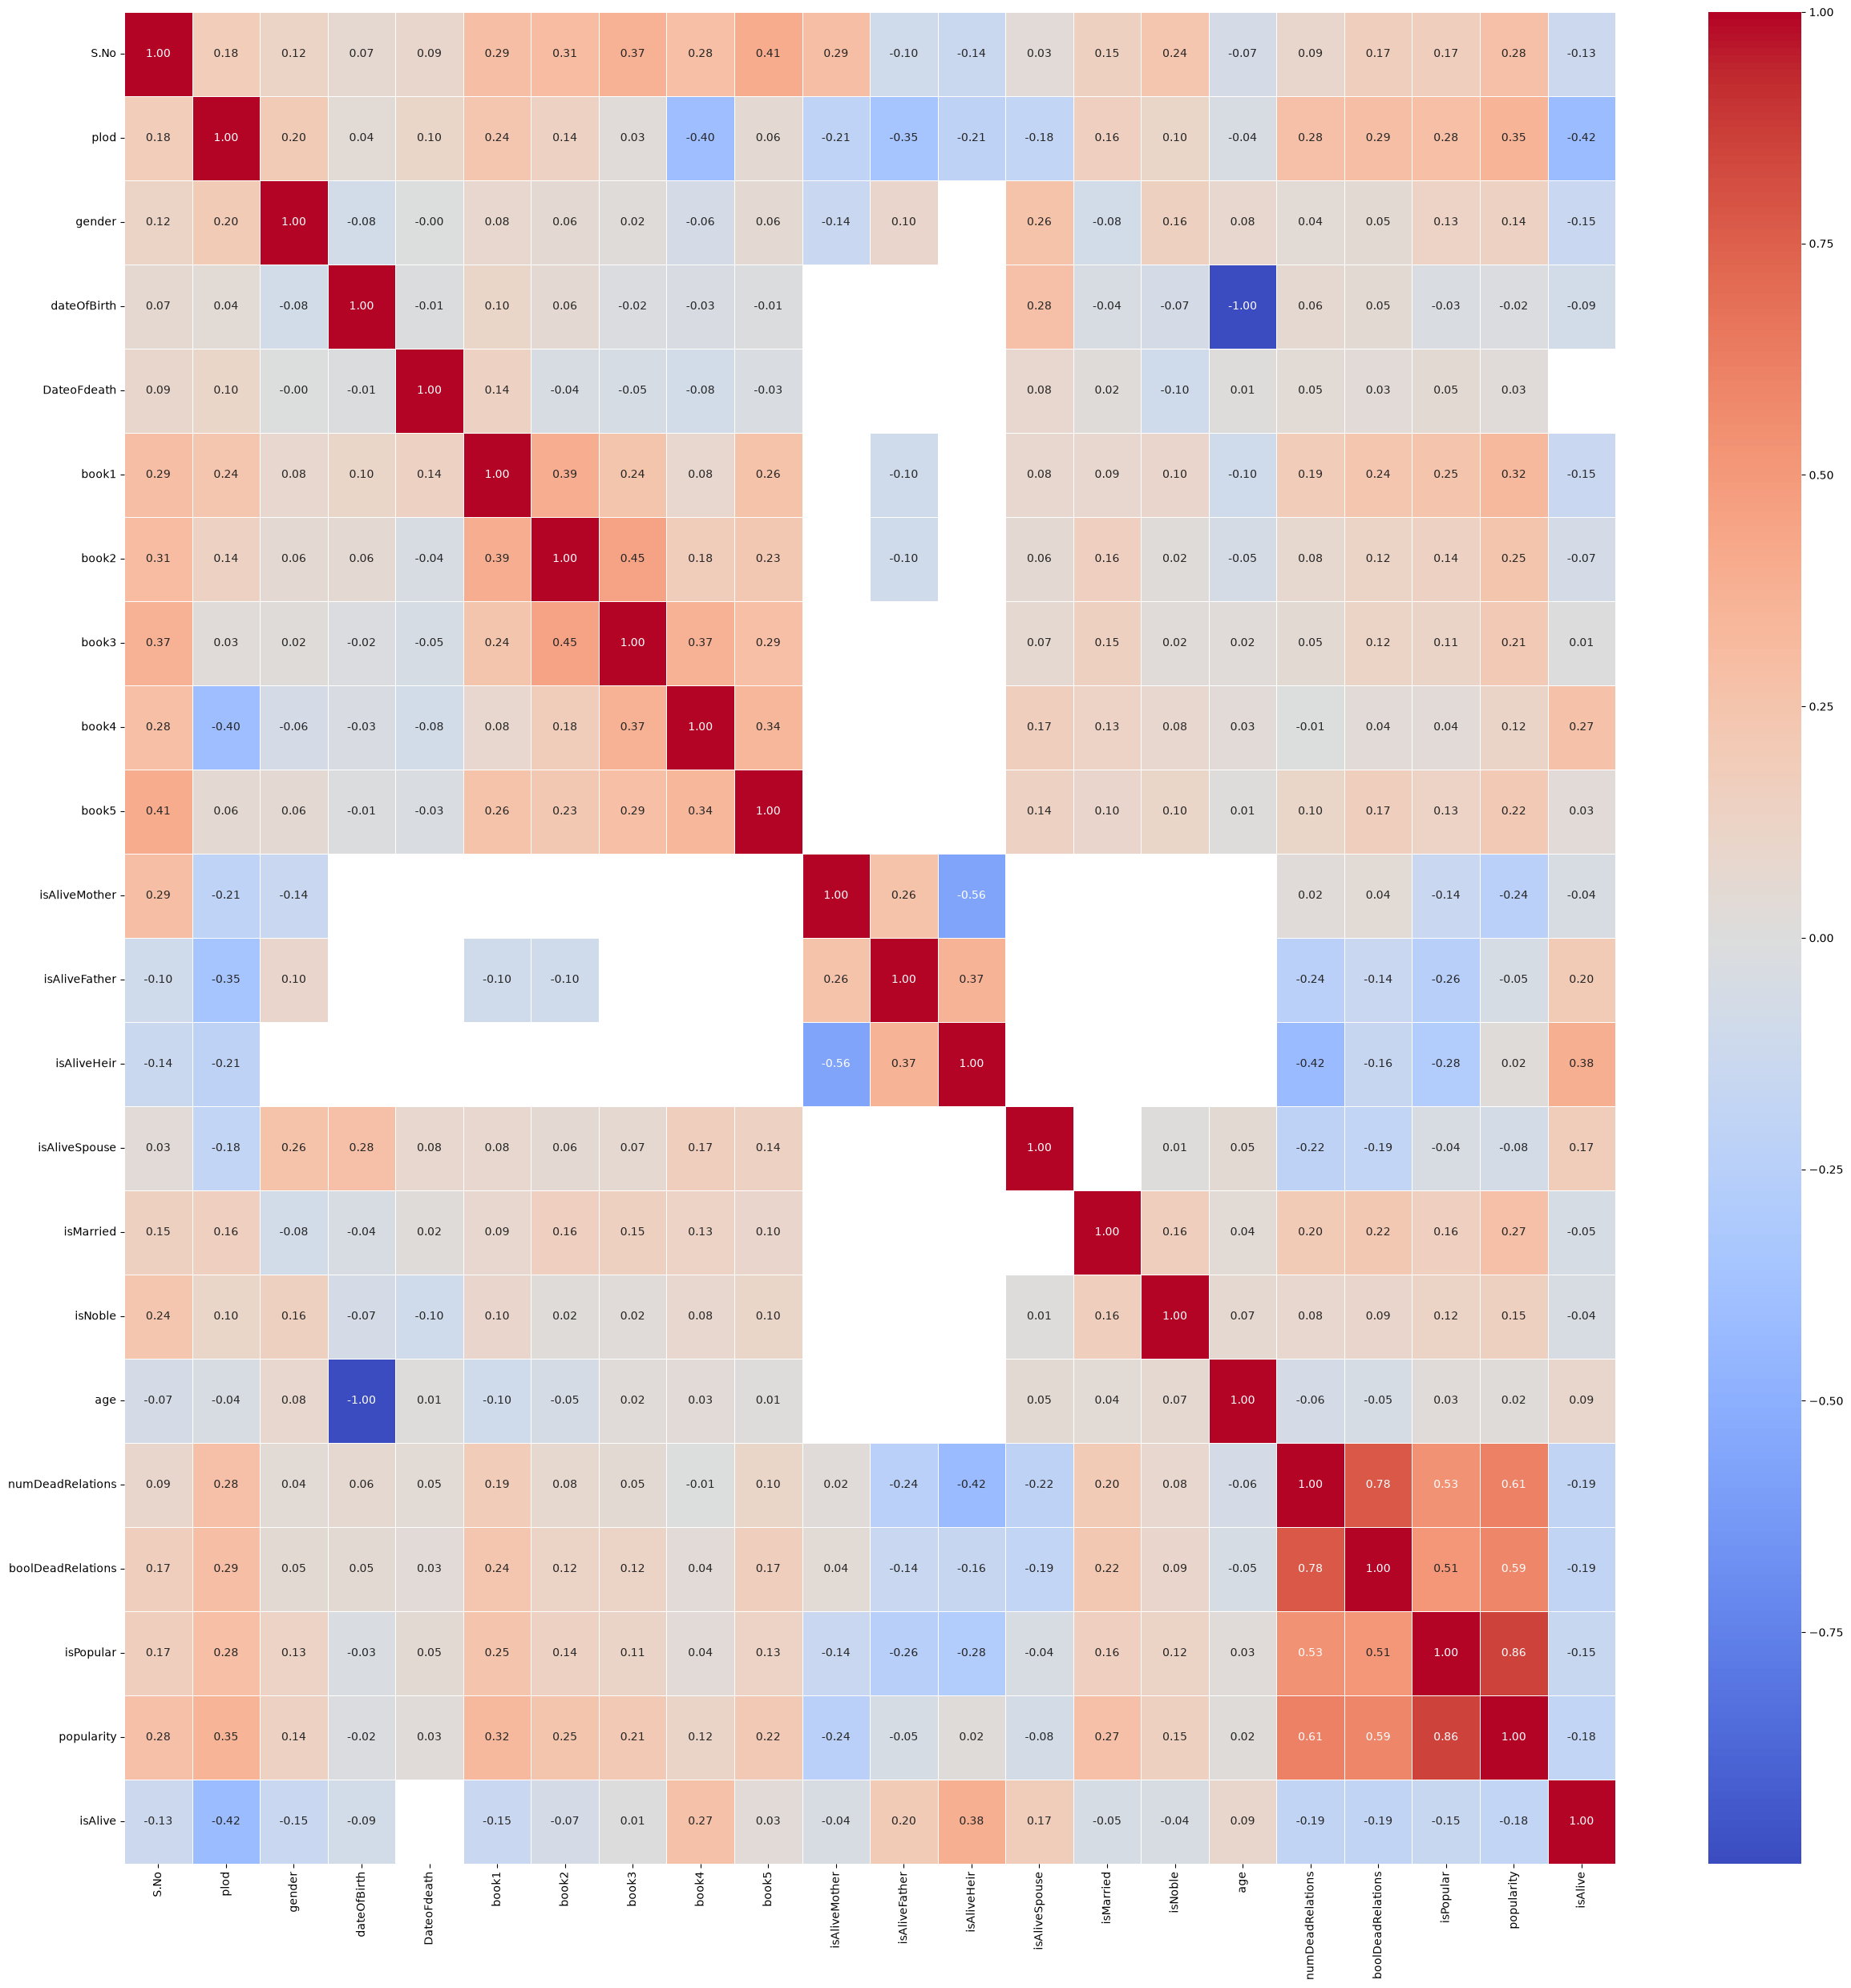

In [393]:
df_corr = df.select_dtypes(include=['int64', 'float64']).corr()
plt.figure(figsize=(30,30))

sns.heatmap(df_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.show()

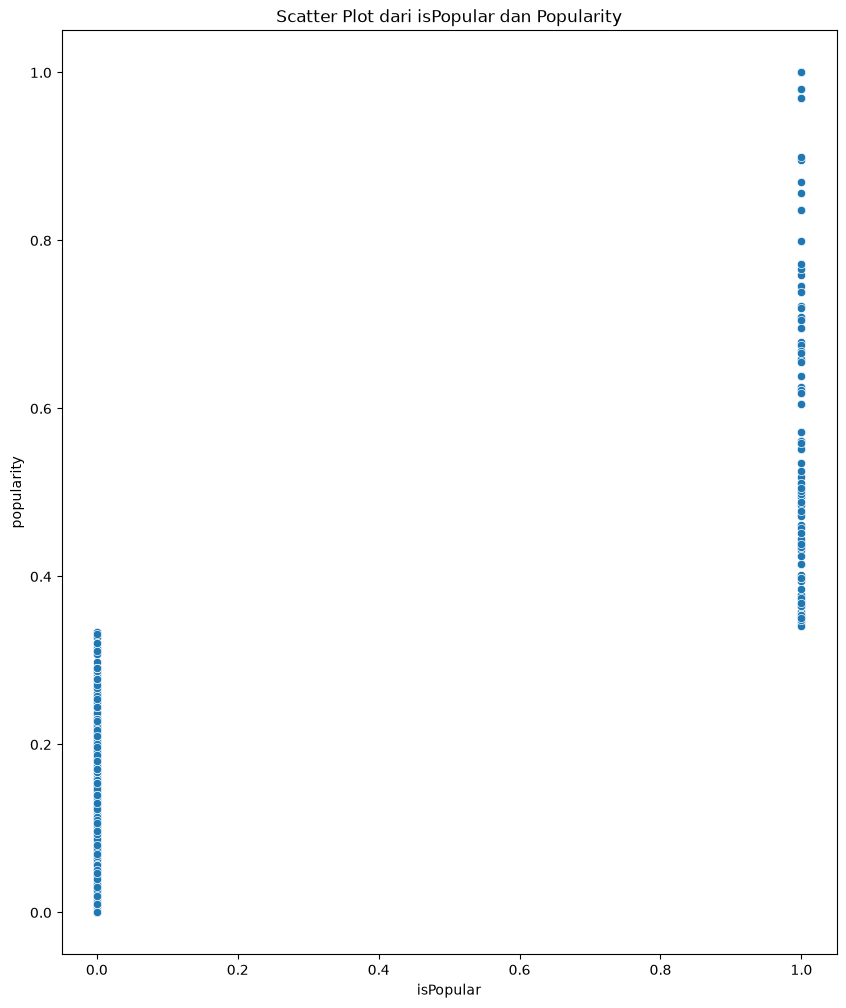

In [394]:
plt.figure(figsize=(10, 12))

sns.scatterplot(x='isPopular', y='popularity', data=df)
plt.title('Scatter Plot dari isPopular dan Popularity')
plt.show()

# **<span id="Data_Pre_Processing" style="color: #2563EB;">4. Data Pre Processing</span>**


In [395]:
df = df.drop(columns=['name', 'S.No', 'dateOfBirth', 'DateoFdeath'])

In [396]:
# 1. Ubah teks nama menjadi: 1 (Kalau punya) dan 0 (Kalau tidak punya)
df['has_mother'] = df['mother'].notnull().astype(int)
df['has_father'] = df['father'].notnull().astype(int)
df['has_heir']   = df['heir'].notnull().astype(int)
df['has_spouse'] = df['spouse'].notnull().astype(int)

# 2. Status hidup keluarganya:
# 1 = Hidup, 0 = Mati, -1 = Tidak tercatat / Tidak punya
for col in ['isAliveMother', 'isAliveFather', 'isAliveHeir', 'isAliveSpouse']:
    df[col] = df[col].fillna(-1)

df = df.drop(columns=['mother', 'father', 'heir', 'spouse'])

In [397]:
df.loc[df['age'] < 0, 'age'] = np.nan

In [398]:
df.head(15)

,plod,title,gender,culture,house,book1,book2,book3,book4,book5,...,age,numDeadRelations,boolDeadRelations,isPopular,popularity,isAlive,has_mother,has_father,has_heir,has_spouse
0,0.946,NaN,1,NaN,NaN,0,0,0,0,0,...,NaN,11,1,1,0.605351,0,1,1,1,0
1,0.613,Lord of the Crossing,1,Rivermen,House Frey,1,1,1,1,1,...,97.0,1,1,1,0.896321,1,0,0,0,1
2,0.507,Ser,1,NaN,House Swyft,0,0,0,1,0,...,NaN,0,0,0,0.267559,1,0,0,0,0
3,0.924,Queen,0,NaN,House Arryn,0,0,0,0,0,...,23.0,0,0,0,0.183946,0,0,0,0,1
4,0.383,Greenstone,0,Dornish,House Santagar,0,0,0,1,0,...,29.0,0,0,0,0.043478,1,0,0,0,1
5,0.979,NaN,1,NaN,NaN,0,0,0,0,0,...,NaN,5,1,1,1.000000,1,1,1,1,0
6,0.986,Hand of the King,1,Valyrian,House Targaryen,0,0,0,0,0,...,26.0,0,0,1,0.431438,0,0,0,0,1
7,0.964,NaN,1,NaN,NaN,0,0,0,0,0,...,NaN,5,1,1,0.678930,0,1,1,1,0
8,0.276,Ser,1,NaN,NaN,0,0,1,0,0,...,NaN,0,0,0,0.006689,0,0,0,0,0
9,0.609,Ser,1,NaN,House Osgrey,0,0,0,0,0,...,NaN,0,0,0,0.020067,1,0,0,0,0


In [399]:
X = df.drop(columns='isAlive')
y = df['isAlive']

In [400]:
def split_data(X, y, train_size=0.8, random_state=42):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    split_ratio = int(train_size * len(X))
    X_train, X_test = X.iloc[idx[:split_ratio]], X.iloc[idx[split_ratio:]]
    y_train, y_test = y.iloc[idx[:split_ratio]], y.iloc[idx[split_ratio:]]
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = split_data(X, y)

In [401]:
# kolom_teks = X_train.select_dtypes(include=['object', 'category', 'string']).columns
# for col in kolom_teks:
#     X_train[col] = X_train[col].fillna(X_train[col].mode()[0])

# kolom_num = X_train.select_dtypes(include=['number']).columns
# for col in kolom_num:
#     X_train[col] = X_train[col].fillna(X_train[col].median())

# # TEST
# kolom_teks = X_test.select_dtypes(include=['object', 'category', 'string']).columns
# for col in kolom_teks:
#     X_test[col] = X_test[col].fillna(X_train[col].mode()[0])

# kolom_num = X_test.select_dtypes(include=['number']).columns
# for col in kolom_num:
#     X_test[col] = X_test[col].fillna(X_test[col].median())



In [402]:

# 1. Mengambil kolom numerik
num_cols = X_train.select_dtypes(include=['number']).columns

# 2. Mengisi missing value numerik menggunakan median
for col in num_cols:
    med = X_train[col].median()

    X_train[col] = X_train[col].fillna(med)
    X_test[col] = X_test[col].fillna(med)


# 3. Mengambil kolom kategorikal
cat_cols = X_train.select_dtypes(include=['object', 'str']).columns

# 4. Mengubah data kategorikal menjadi angka
for col in cat_cols:
    X_train[col], uniques = pd.factorize(
        X_train[col].fillna('Unknown')
    )

    X_test[col] = uniques.get_indexer(
        X_test[col].fillna('Unknown')
    )


In [403]:
cols = X_train.select_dtypes(include=['number']).columns

Q1 = X_train[cols].quantile(0.25)
Q3 = X_train[cols].quantile(0.75)

IQR = Q3 - Q1 

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((X_train[cols] < batas_bawah) | (X_train[cols] > batas_atas)).sum()

hasil = pd.DataFrame({'Outlier': outlier, 'Persentase': outlier / len(X_train) * 100})
hasil.sort_values(by='Outlier', ascending=False)


,Outlier,Persentase
age,341,21.915167
book1,305,19.601542
title,276,17.737789
isAliveSpouse,234,15.038560
isMarried,234,15.038560
has_spouse,234,15.038560
culture,192,12.339332
popularity,165,10.604113
boolDeadRelations,121,7.776350
numDeadRelations,121,7.776350


In [404]:
# 5. Mengubah DataFrame menjadi NumPy array
X_train = X_train.values
X_test = X_test.values

y_train = y_train.values
y_test = y_test.values

print(X_train)
print(y_train)
print(X_test)
print(y_test)


[[ 0.273  0.     1.    ...  0.     0.     0.   ]
 [ 0.261  1.     1.    ...  0.     0.     0.   ]
 [ 0.685  0.     1.    ...  0.     0.     0.   ]
 ...
 [ 0.341  0.     1.    ...  0.     0.     0.   ]
 [ 0.959  3.     1.    ...  0.     0.     0.   ]
 [ 0.075 52.     1.    ...  0.     0.     1.   ]]
[0 1 0 ... 1 0 1]
[[  0.633 158.      1.    ...   0.      0.      0.   ]
 [  0.535  -1.      1.    ...   0.      0.      0.   ]
 [  0.947  56.      1.    ...   0.      0.      0.   ]
 ...
 [  0.468   0.      1.    ...   0.      0.      0.   ]
 [  0.338   3.      1.    ...   0.      0.      1.   ]
 [  0.275   3.      1.    ...   0.      0.      0.   ]]
[0 1 1 1 0 1 0 1 0 1 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 0 1 1 0 1 0 1 0 1 0 1 1
 1 1 1 1 1 1 1 0 1 0 1 1 0 1 0 1 1 1 1 1 1 0 0 0 1 1 1 0 1 1 1 1 1 1 0 1 0
 1 1 1 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 0 1 0 1 1
 1 1 1 1 1 0 1 1 0 0 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 1 1 1 0 0 0 0 1 1 1 1 0
 1 1 1 1 1 1 0 1 0 1 1 0 1 1 1 1 1 1 1 0 1 0 1

# **5. Modelling**

In [ ]:
FITUR = X_train.columns.tolist() # mengimportkan kolom fitur secara otomatis

